# **APLICACIÓN DE UN MODELO DE MACHINE LEARNING DE REGRESIÓN LINEAL**
### Predicción de ventas — BigMart Sales

**Integrantes:**
* Pereda Chávez Jesús Manuel — 22111357
* Castro Sánchez Luis Adán — 22111352
* Antonio Altamirano Jesús Isaac — 22111389
* Gardea González Ricardo Jovany — 22111408

Este notebook integra lo mejor del trabajo de cada integrante:
* **Base y estructura del ejemplo:** pipeline con `ColumnTransformer`, partición 80:20, métricas RMSE y R².
* **Pereda:** limpieza inteligente de nulos y ceros, `Item_Category`, `Non-Edible`, logaritmo en ventas/precio/visibilidad, interacciones precio × tienda, corrección de Duan (smearing).
* **Castro:** comparación contra Random Forest con la misma partición y verificación del objetivo R² ≥ 0.70.
* **JIAA:** gráfica de ventas reales vs. predichas e interpretación de coeficientes.

## 1. Configuración y carga de datos
**Cambia solo la variable `RUTA_CSV`** a donde tengas el archivo en tu Drive.

In [7]:
# Montar Google Drive (si no estás en Colab, se omite y se usa la ruta local)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('No se está ejecutando en Colab: se usará la ruta local.')

RUTA_CSV = '/content/drive/MyDrive/IA/bigMartSales.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


En esta actividad se usa el archivo `bigMartSales.csv`:

* `Item_Identifier`: ID de producto único
* `Item_Weight`: peso del producto
* `Item_Fat_Content`: si el producto es bajo en grasa o no
* `Item_Visibility`: porcentaje del área de exhibición total de la tienda asignado al producto
* `Item_Type`: categoría a la que pertenece el producto
* `Item_MRP`: precio máximo de venta (precio de lista) del producto
* `Outlet_Identifier`: ID de tienda única
* `Outlet_Establishment_Year`: año en que se estableció la tienda
* `Outlet_Size`: tamaño de la tienda en superficie cubierta
* `Outlet_Location_Type`: tipo de ciudad en la que se encuentra la tienda
* `Outlet_Type`: si es tienda de abarrotes o algún tipo de supermercado
* **`Item_Outlet_Sales`**: ventas del producto en la tienda. **Es la variable a predecir.**

In [8]:
# Librerías para manipulación de datos
import numpy as np
import pandas as pd

# Librerías para visualización
import seaborn as sns
import matplotlib.pyplot as plt

# Preprocesamiento
from sklearn.impute import SimpleImputer          # rellena datos faltantes (mean, median, most_frequent...)
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
    # MinMaxScaler: escala los datos numéricos al rango [0,1]
    # OneHotEncoder: convierte categorías (texto) en columnas binarias 0/1

# Canalización (pipeline)
from sklearn.compose import ColumnTransformer, make_column_selector
    # ColumnTransformer: aplica distintas transformaciones a distintas columnas
    # make_column_selector: selecciona columnas automáticamente según su tipo de dato
from sklearn.pipeline import make_pipeline
    # encadena preprocesamiento + modelo en una sola estructura

# Modelos y métricas
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
    # RMSE: error promedio en las unidades de la variable objetivo (menor = mejor)
    # R2: proporción de la variabilidad que explica el modelo (1 = perfecto, 0 = igual que el promedio)

Se guardan todos los registros en el dataframe `sales_df` (y una copia original `raw_df` para el modelo base).

In [9]:
sales_df = pd.read_csv(RUTA_CSV)
raw_df = sales_df.copy()   # copia sin modificar, se usará para el modelo base de comparación
sales_df

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009,Medium,Tier 3,Supermarket Type2,1845.5976


## 2. Análisis de datos

In [10]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [11]:
# Cantidad de valores únicos por columna
sales_df.nunique()

,0
Item_Identifier,1559
Item_Weight,415
Item_Fat_Content,5
Item_Visibility,7880
Item_Type,16
Item_MRP,5938
Outlet_Identifier,10
Outlet_Establishment_Year,9
Outlet_Size,3
Outlet_Location_Type,3


`Item_Identifier` es solo un ID, por lo que **no se usa directamente como predictor**. Antes de eliminarla se guarda en `item_ids` (sirve para rellenar valores faltantes por producto) y se crea una categoría general con sus dos primeras letras: `FD` = comida, `DR` = bebidas, `NC` = no consumibles.

`Outlet_Identifier` **sí se conserva**: cada tienda tiene un comportamiento de ventas propio y eso mejora mucho el modelo.

In [12]:
item_ids = sales_df['Item_Identifier'].copy()
sales_df['Item_Category'] = sales_df['Item_Identifier'].str[:2]
sales_df.drop('Item_Identifier', axis=1, inplace=True)

In [13]:
# Estadísticas descriptivas de las variables numéricas
sales_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Item_Weight,7060.0,12.857645,4.643456,4.555,8.773750,12.600000,16.850000,21.350000
Item_Visibility,8523.0,0.066132,0.051598,0.000,0.026989,0.053931,0.094585,0.328391
Item_MRP,8523.0,140.992782,62.275067,31.290,93.826500,143.012800,185.643700,266.888400
Outlet_Establishment_Year,8523.0,1997.831867,8.371760,1985.000,1987.000000,1999.000000,2004.000000,2009.000000
Item_Outlet_Sales,8523.0,2181.288914,1706.499616,33.290,834.247400,1794.331000,3101.296400,13086.964800


In [14]:
# Estadísticas descriptivas de las variables de texto
sales_df.describe(exclude=np.number).T

,count,unique,top,freq
Item_Fat_Content,8523,5,Low Fat,5089
Item_Type,8523,16,Fruits and Vegetables,1232
Outlet_Identifier,8523,10,OUT027,935
Outlet_Size,6113,3,Medium,2793
Outlet_Location_Type,8523,3,Tier 3,3350
Outlet_Type,8523,4,Supermarket Type1,5577
Item_Category,8523,3,FD,6125


In [15]:
# Listas de variables numéricas y categóricas
num_cols = sales_df.select_dtypes(include=np.number).columns.tolist()
cat_cols = sales_df.select_dtypes(exclude=np.number).columns.tolist()

In [16]:
# Recuento de cada categoría única en las variables categóricas
for column in cat_cols:
    print(column)
    print(sales_df[column].value_counts())
    print('-' * 50)

Item_Fat_Content
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64
--------------------------------------------------
Item_Type
Item_Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64
--------------------------------------------------
Outlet_Identifier
Outlet_Identifier
OUT027    935
OUT013    932
OUT035    930
OUT049    930
OUT046    930
OUT045    929
OUT018    928
OUT017    926
OUT010    555
OUT019    528
Name: count, dtype: int64
------------------------------

In [17]:
# Porcentaje de nulos por columna
sales_df.isnull().mean() * 100

,0
Item_Weight,17.165317
Item_Fat_Content,0.000000
Item_Visibility,0.000000
Item_Type,0.000000
Item_MRP,0.000000
Outlet_Identifier,0.000000
Outlet_Establishment_Year,0.000000
Outlet_Size,28.276428
Outlet_Location_Type,0.000000
Outlet_Type,0.000000


### Limpieza de valores faltantes y valores inválidos

* `Item_Weight`: un mismo producto siempre pesa lo mismo, así que se rellena con el peso de ese producto en otras tiendas (y con la mediana si aparece una sola vez).
* `Item_Visibility`: hay valores en 0 que no tienen sentido (todo producto ocupa algo de exhibición). Se tratan como faltantes y se rellenan con el promedio de ese producto en otras tiendas.
* `Outlet_Size`: hay tiendas sin tamaño registrado. Se rellena con la moda del tamaño de las tiendas del mismo tipo y ubicación.

In [18]:
# Item_Weight: peso promedio del mismo producto; si no hay, la mediana
sales_df['Item_Weight'] = sales_df['Item_Weight'].fillna(sales_df.groupby(item_ids)['Item_Weight'].transform('mean'))
sales_df['Item_Weight'] = sales_df['Item_Weight'].fillna(sales_df['Item_Weight'].median())

# Item_Visibility: los 0 se consideran faltantes y se rellenan con el promedio del producto
vis = sales_df['Item_Visibility'].replace(0, np.nan)
sales_df['Item_Visibility'] = vis.fillna(vis.groupby(item_ids).transform('mean')).fillna(vis.median())

# Outlet_Size: moda por tipo y ubicación de tienda
sales_df['Outlet_Size'] = sales_df['Outlet_Size'].fillna(
    sales_df.groupby(['Outlet_Type', 'Outlet_Location_Type'])['Outlet_Size']
            .transform(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan))
sales_df['Outlet_Size'] = sales_df['Outlet_Size'].fillna('Small')

sales_df.isnull().sum()

,0
Item_Weight,0
Item_Fat_Content,0
Item_Visibility,0
Item_Type,0
Item_MRP,0
Outlet_Identifier,0
Outlet_Establishment_Year,0
Outlet_Size,0
Outlet_Location_Type,0
Outlet_Type,0


### Análisis univariado de variables numéricas

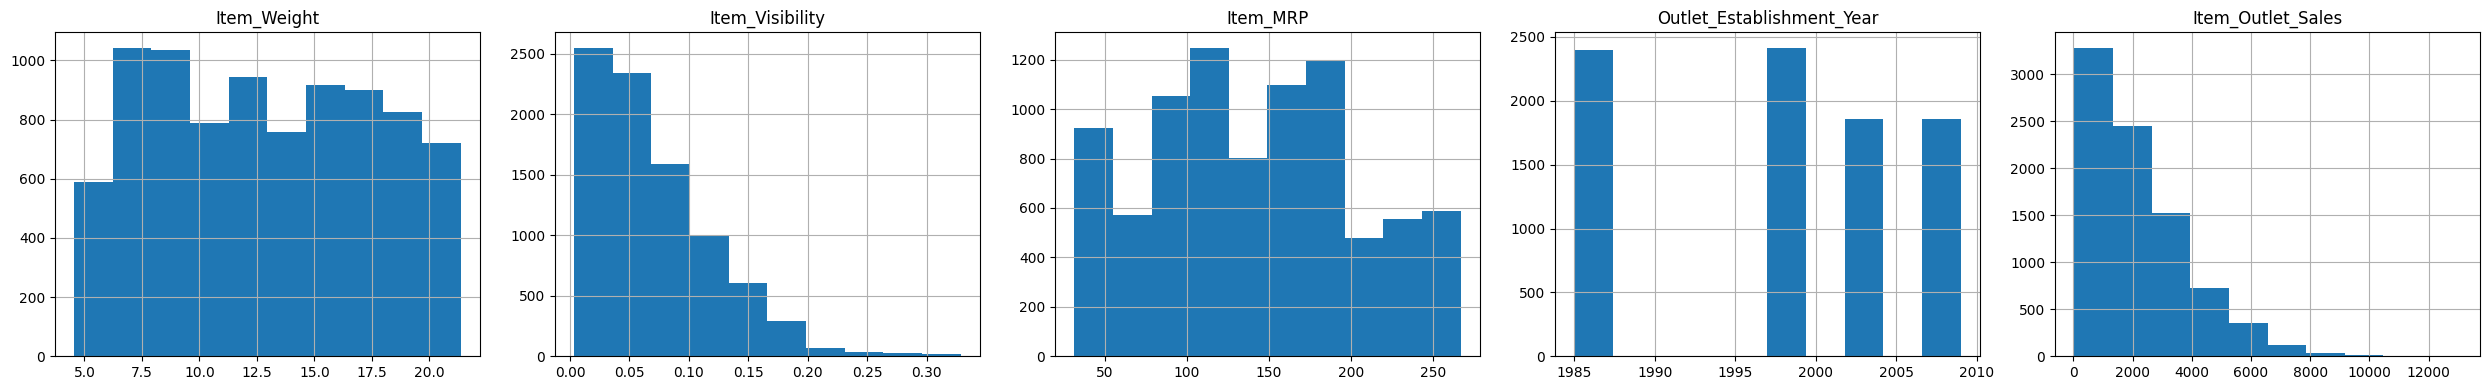

In [19]:
n = len(num_cols)
sales_df[num_cols].hist(figsize=(5*n, 4), layout=(1, n))
plt.tight_layout()
plt.show()

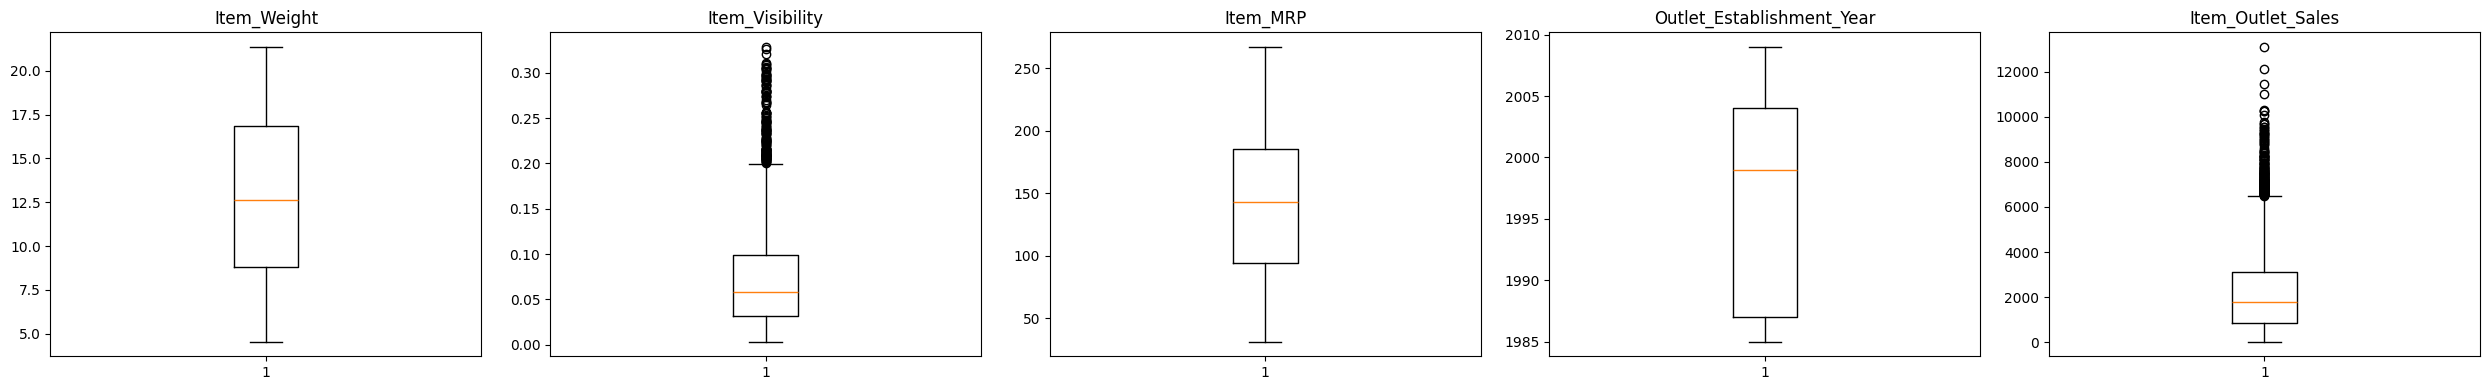

In [20]:
fig, axes = plt.subplots(1, n, figsize=(5*n, 4))
axes = np.atleast_1d(axes).ravel()
for col, ax in zip(num_cols, axes):
    ax.boxplot(sales_df[col].dropna())
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Análisis univariado de variables categóricas

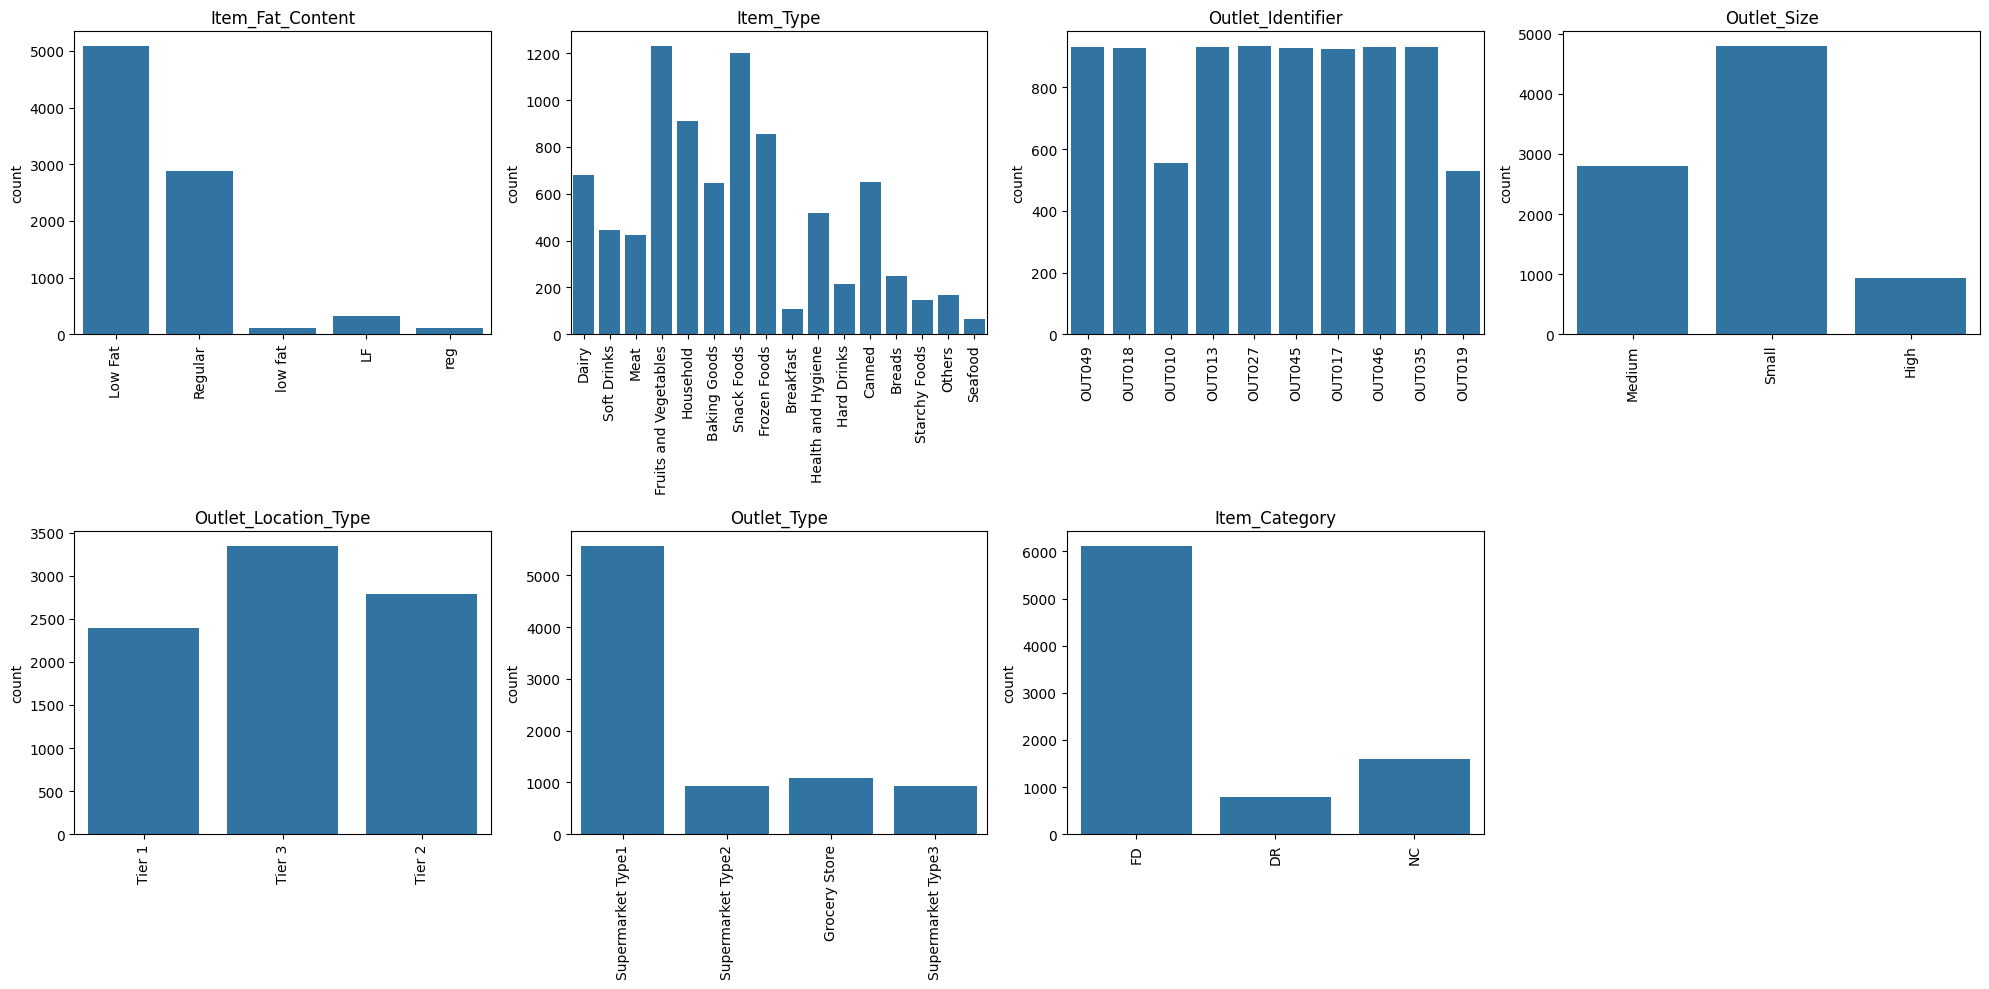

In [21]:
k = len(cat_cols)
fig, axes = plt.subplots(2, (k+1)//2, figsize=(5*((k+1)//2), 10))
axes = axes.ravel()
for col, ax in zip(cat_cols, axes):
    sns.countplot(x=sales_df[col], ax=ax)
    ax.set(title=f'{col}', xlabel=None)
    ax.tick_params(axis='x', rotation=90)
for ax in axes[k:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

En `Item_Fat_Content` hay categorías expresadas de diferente forma:
* Low Fat = low fat = LF
* Regular = reg

Se unifican para dejar solo dos valores: `Low Fat` y `Regular`. Además, los productos no consumibles (`NC`) no pueden tener grasa, por lo que se les asigna la categoría `Non-Edible`.

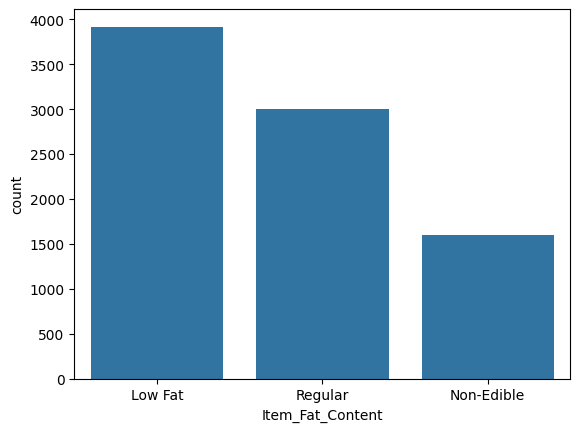

In [22]:
sales_df['Item_Fat_Content'] = sales_df['Item_Fat_Content'].replace({'low fat': 'Low Fat', 'LF': 'Low Fat', 'reg': 'Regular'})
sales_df.loc[sales_df['Item_Category'] == 'NC', 'Item_Fat_Content'] = 'Non-Edible'
sns.countplot(x=sales_df['Item_Fat_Content'])
plt.show()

### Análisis bivariado

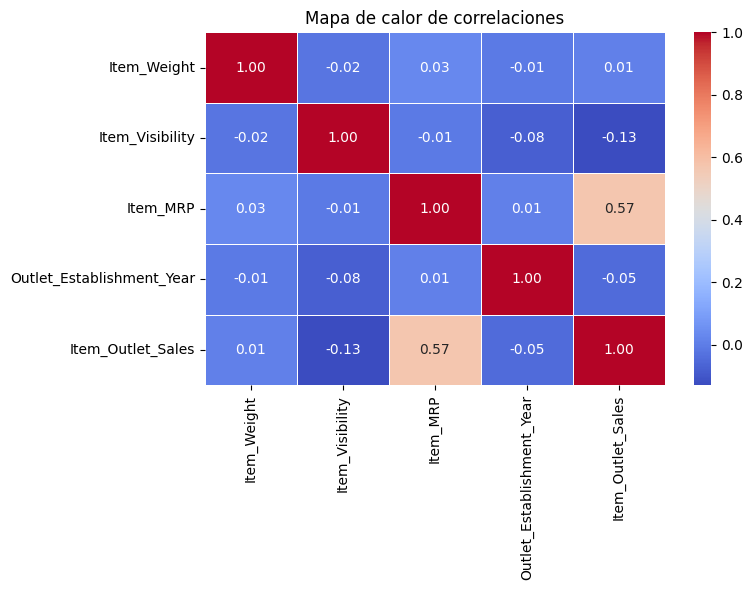

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(sales_df.corr(numeric_only=True).round(2), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Mapa de calor de correlaciones')
plt.tight_layout()
plt.show()

Del gráfico anterior, parece que solo `Item_MRP` tiene una relación lineal moderada con `Item_Outlet_Sales`. Se verifica con diagramas de dispersión.

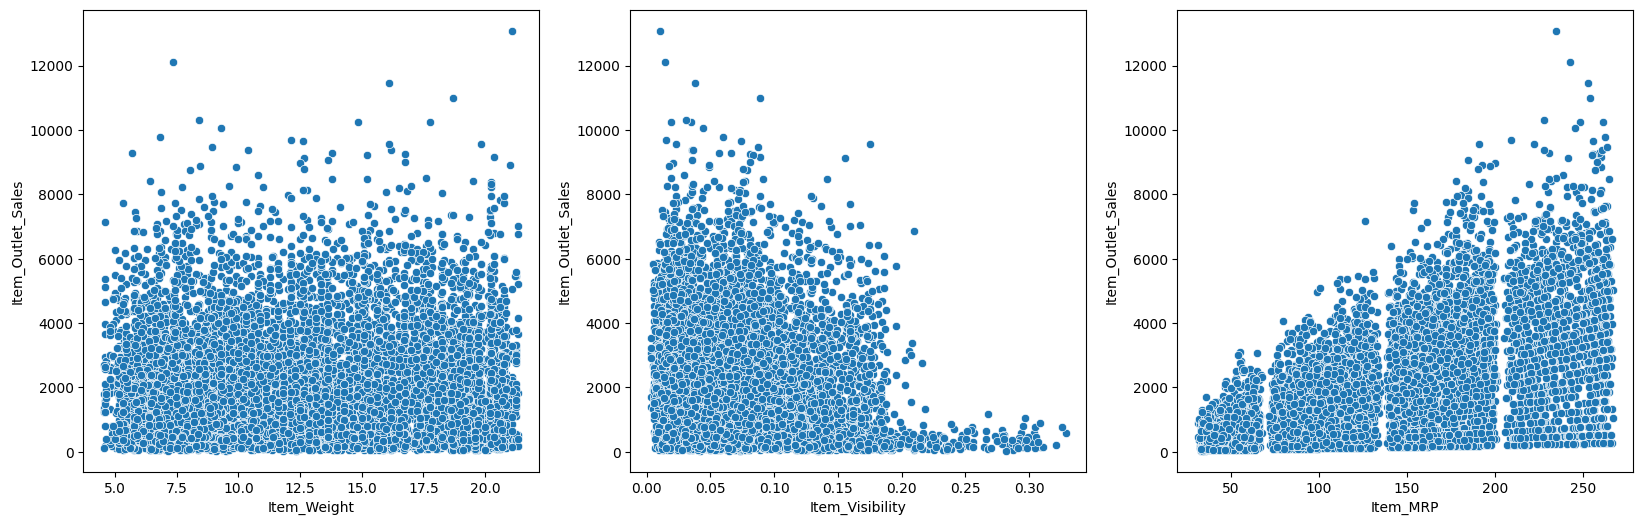

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.scatterplot(x='Item_Weight', y='Item_Outlet_Sales', data=sales_df, ax=axes[0])
sns.scatterplot(x='Item_Visibility', y='Item_Outlet_Sales', data=sales_df, ax=axes[1])
sns.scatterplot(x='Item_MRP', y='Item_Outlet_Sales', data=sales_df, ax=axes[2])
plt.show()

Se crea la característica `Outlet_Age` (antigüedad de la tienda). Se usa **2013 como año de referencia** (año de los datos) para que el resultado sea siempre reproducible, sin depender de la fecha en que se ejecute el notebook.

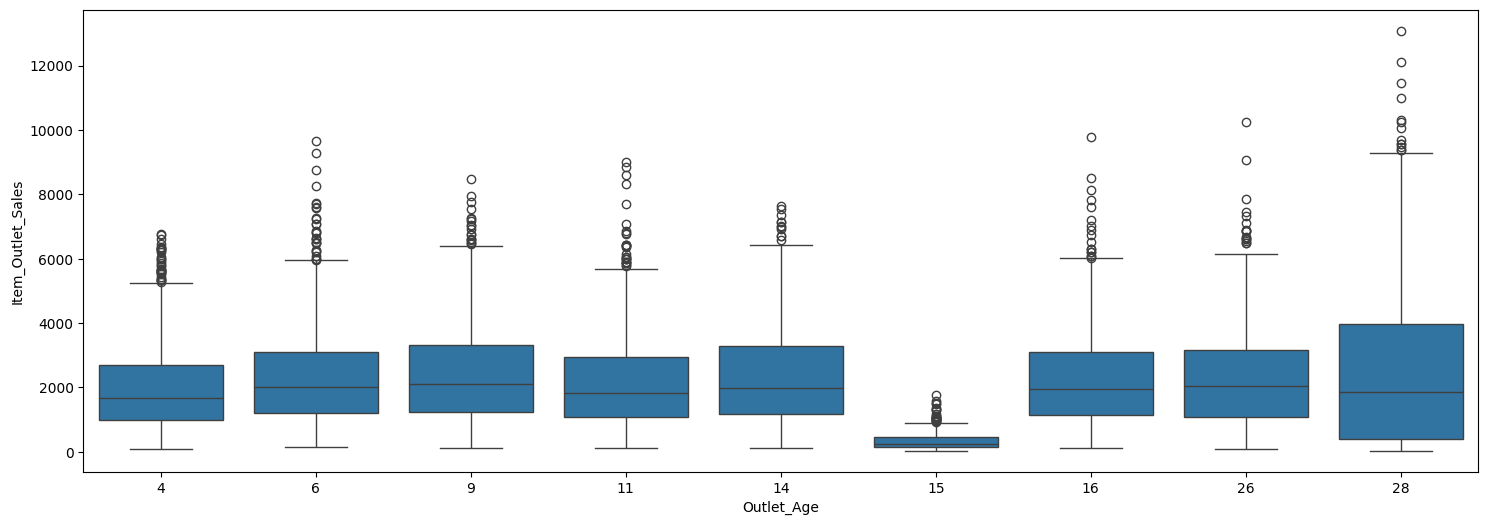

In [25]:
sales_df['Outlet_Age'] = 2013 - sales_df['Outlet_Establishment_Year']   # edad de cada tienda en años
sales_df.drop('Outlet_Establishment_Year', axis=1, inplace=True)         # ya fue transformada

plt.figure(figsize=(18, 6))
sns.boxplot(x='Outlet_Age', y='Item_Outlet_Sales', data=sales_df)
plt.show()

## 3. Inicio del modelo de Machine Learning

### Transformaciones para mejorar el modelo

1. `Item_Outlet_Sales` está muy sesgada a la derecha, por eso se modela su **logaritmo**. El error queda más parejo y la relación con el precio es más lineal.
2. Se usa `log(Item_MRP)` y `log(Item_Visibility)`.
3. Cada tienda tiene su propia relación entre precio y ventas, por lo que se crean **interacciones** `log(Item_MRP)` × tienda. La regresión sigue siendo lineal, pero con una pendiente de precio distinta por tienda.
4. Se eliminan `Item_Weight` e `Item_Type`: no aportan información útil (el peso no influye en las ventas y el tipo de producto ya queda resumido en `Item_Category`), solo agregan ruido.

In [26]:
# Transformación logarítmica de variables sesgadas
sales_df['Log_MRP'] = np.log(sales_df['Item_MRP'])
sales_df['Log_Visibility'] = np.log(sales_df['Item_Visibility'])
sales_df.drop(['Item_Visibility', 'Item_Weight', 'Item_Type'], axis=1, inplace=True)

# Interacción: efecto del precio distinto en cada tienda
for outlet in sorted(sales_df['Outlet_Identifier'].unique()):
    sales_df[f'Log_MRP_x_{outlet}'] = sales_df['Log_MRP'] * (sales_df['Outlet_Identifier'] == outlet)

sales_df.shape

(8523, 21)

### Ingeniería de características
Se especifican las variables de entrada `X` (características) y la variable de salida `y` (objetivo, en escala logarítmica).

In [27]:
X = sales_df.drop('Item_Outlet_Sales', axis=1)   # variables de entrada
y = np.log(sales_df['Item_Outlet_Sales'])        # variable objetivo (log de ventas)

### Partición del conjunto de datos (80:20)

In [28]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y,
                                                train_size=0.8,    # 80% entrenamiento, 20% prueba
                                                random_state=1)    # misma partición siempre
print('Entrenamiento:', Xtrain.shape, '| Prueba:', Xtest.shape)

Entrenamiento: (6818, 20) | Prueba: (1705, 20)


### Procesamiento: canalización (pipeline)

In [29]:
# Numéricas: mediana para nulos + MinMaxScaler [0,1]
num_pipeline = make_pipeline(SimpleImputer(strategy='median'), MinMaxScaler())

# Categóricas: moda para nulos + OneHot
#   drop='first'            -> evita la multicolinealidad (trampa de variables dummy)
#   handle_unknown='ignore' -> ignora categorías nuevas no vistas en el entrenamiento
#   sparse_output=False     -> devuelve matriz densa
cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'),
                             OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))

# Une ambos preprocesamientos detectando las columnas por tipo de dato
preprocessing = ColumnTransformer([
    ('num', num_pipeline, make_column_selector(dtype_include=np.number)),
    ('cat', cat_pipeline, make_column_selector(dtype_exclude=np.number))])

In [30]:
# (Opcional) Para visualizar los cambios que produce el preprocesamiento
Xtrain_prepared = preprocessing.fit_transform(Xtrain)
Xtrain_prepared_df = pd.DataFrame(Xtrain_prepared, columns=preprocessing.get_feature_names_out(), index=Xtrain.index)
print('Número de predictores después del procesamiento:', Xtrain_prepared_df.shape[1])
Xtrain_prepared_df

Número de predictores después del procesamiento: 34


,num__Item_MRP,num__Outlet_Age,num__Log_MRP,num__Log_Visibility,num__Log_MRP_x_OUT010,num__Log_MRP_x_OUT013,num__Log_MRP_x_OUT017,num__Log_MRP_x_OUT018,num__Log_MRP_x_OUT019,num__Log_MRP_x_OUT027,...,cat__Outlet_Identifier_OUT049,cat__Outlet_Size_Medium,cat__Outlet_Size_Small,cat__Outlet_Location_Type_Tier 2,cat__Outlet_Location_Type_Tier 3,cat__Outlet_Type_Supermarket Type1,cat__Outlet_Type_Supermarket Type2,cat__Outlet_Type_Supermarket Type3,cat__Item_Category_FD,cat__Item_Category_NC
1945,0.681925,0.000000,0.846238,0.712034,0.000000,0.0,0.000000,0.942083,0.000000,0.000000,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
1720,0.615374,0.000000,0.806484,0.851813,0.000000,0.0,0.000000,0.926813,0.000000,0.000000,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
1954,0.824788,0.083333,0.921612,0.600181,0.000000,0.0,0.970707,0.000000,0.000000,0.000000,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
1919,0.312702,0.000000,0.564630,0.844912,0.000000,0.0,0.000000,0.833913,0.000000,0.000000,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2461,0.423207,0.208333,0.667998,0.622905,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2895,0.531008,1.000000,0.750669,0.962717,0.000000,0.0,0.000000,0.000000,0.904520,0.000000,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7813,0.100619,1.000000,0.263096,0.864758,0.000000,0.0,0.000000,0.000000,0.717412,0.000000,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
905,0.500067,0.500000,0.728402,0.644399,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
5192,0.054833,0.458333,0.161239,0.581920,0.678279,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


## 4. Entrenamiento del modelo de regresión lineal

In [31]:
# Pipeline completo: preprocesamiento + regresión lineal
lr_model = make_pipeline(preprocessing, LinearRegression())

# Entrena todo el pipeline (ytrain está en escala logarítmica)
lr_model.fit(Xtrain, ytrain)

# Predicciones sobre los datos de prueba
predictions = lr_model.predict(Xtest)

# --- Métricas en escala logarítmica (en la que se entrenó el modelo) ---
r2_log = r2_score(ytest, predictions)
rmse_log = np.sqrt(mean_squared_error(ytest, predictions))
print('R2 (escala logarítmica):  ', round(r2_log, 4))
print('RMSE (escala logarítmica):', round(rmse_log, 4))

# --- Métricas en escala original de ventas ---
# exp() regresa a ventas reales; el factor de Duan (smearing) corrige el sesgo de la transformación log
smearing = np.mean(np.exp(ytrain - lr_model.predict(Xtrain)))
pred_sales = np.exp(predictions) * smearing
real_sales = np.exp(ytest)
rmse_orig = np.sqrt(mean_squared_error(real_sales, pred_sales))
r2_orig = r2_score(real_sales, pred_sales)
print('RMSE (ventas originales): ', round(rmse_orig, 2))
print('R2 (ventas originales):   ', round(r2_orig, 4))

if r2_log >= 0.70:
    print('\nObjetivo alcanzado: R2 logarítmico igual o superior a 0.70.')
else:
    print('\nEl R2 logarítmico es menor a 0.70.')

R2 (escala logarítmica):   0.7512
RMSE (escala logarítmica): 0.5247
RMSE (ventas originales):  1084.29
R2 (ventas originales):    0.6034

Objetivo alcanzado: R2 logarítmico igual o superior a 0.70.


## 5. Comparación contra el modelo base

Para comprobar la mejora se entrena el **modelo base** del ejemplo (regresión lineal simple sobre las variables originales, sin limpieza avanzada ni logaritmos) con **exactamente las mismas filas** de entrenamiento y prueba.

In [32]:
# --- MODELO BASE (el del ejemplo original) con las mismas filas de train/test ---
base = raw_df.copy()
base['Item_Fat_Content'] = base['Item_Fat_Content'].replace({'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})
base['Outlet_Age'] = 2013 - base['Outlet_Establishment_Year']
base = base.drop(['Item_Identifier', 'Outlet_Identifier', 'Outlet_Establishment_Year'], axis=1)

Xb = base.drop('Item_Outlet_Sales', axis=1)
yb = base['Item_Outlet_Sales']
Xb_train, Xb_test = Xb.loc[Xtrain.index], Xb.loc[Xtest.index]
yb_train, yb_test = yb.loc[Xtrain.index], yb.loc[Xtest.index]

base_prep = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), MinMaxScaler()), make_column_selector(dtype_include=np.number)),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)),
                          make_column_selector(dtype_exclude=np.number))])
base_model = make_pipeline(base_prep, LinearRegression())
base_model.fit(Xb_train, yb_train)
pred_base = base_model.predict(Xb_test)

rmse_base = np.sqrt(mean_squared_error(yb_test, pred_base))
r2_base = r2_score(yb_test, pred_base)
print('MODELO BASE -> RMSE:', round(rmse_base, 2), '| R2:', round(r2_base, 4))

MODELO BASE -> RMSE: 1144.38 | R2: 0.5582


### Modelo alternativo: Random Forest
Se entrena un Random Forest con **el mismo preprocesamiento, la misma partición y el mismo objetivo logarítmico**, solo como referencia para saber qué tan lejos queda la regresión lineal de un modelo no lineal.

In [33]:
rf_model = make_pipeline(preprocessing,
                         RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=1, n_jobs=-1))
rf_model.fit(Xtrain, ytrain)
pred_rf_log = rf_model.predict(Xtest)

r2_rf_log = r2_score(ytest, pred_rf_log)
smear_rf = np.mean(np.exp(ytrain - rf_model.predict(Xtrain)))
pred_rf_sales = np.exp(pred_rf_log) * smear_rf
rmse_rf = np.sqrt(mean_squared_error(real_sales, pred_rf_sales))
r2_rf_orig = r2_score(real_sales, pred_rf_sales)
print('RANDOM FOREST -> R2 log:', round(r2_rf_log, 4), '| R2 original:', round(r2_rf_orig, 4), '| RMSE original:', round(rmse_rf, 2))

RANDOM FOREST -> R2 log: 0.7161 | R2 original: 0.533 | RMSE original: 1176.59


In [34]:
# Tabla resumen (todas las ventas en escala original para que sean comparables)
resumen = pd.DataFrame({
    'Modelo': ['Base (ejemplo original)', 'Regresión lineal mejorada', 'Random Forest (referencia)'],
    'R2 (ventas originales)': [r2_base, r2_orig, r2_rf_orig],
    'RMSE (ventas originales)': [rmse_base, rmse_orig, rmse_rf],
    'R2 (escala log)': [np.nan, r2_log, r2_rf_log]
}).round(4)
resumen

,Modelo,R2 (ventas originales),RMSE (ventas originales),R2 (escala log)
0,Base (ejemplo original),0.5582,1144.3828,NaN
1,Regresión lineal mejorada,0.6034,1084.2906,0.7512
2,Random Forest (referencia),0.5330,1176.5897,0.7161


## 6. Análisis gráfico de resultados

Si el modelo fuera perfecto, todos los puntos formarían una línea diagonal. Se comparan las ventas reales contra las predichas, en escala original y logarítmica.

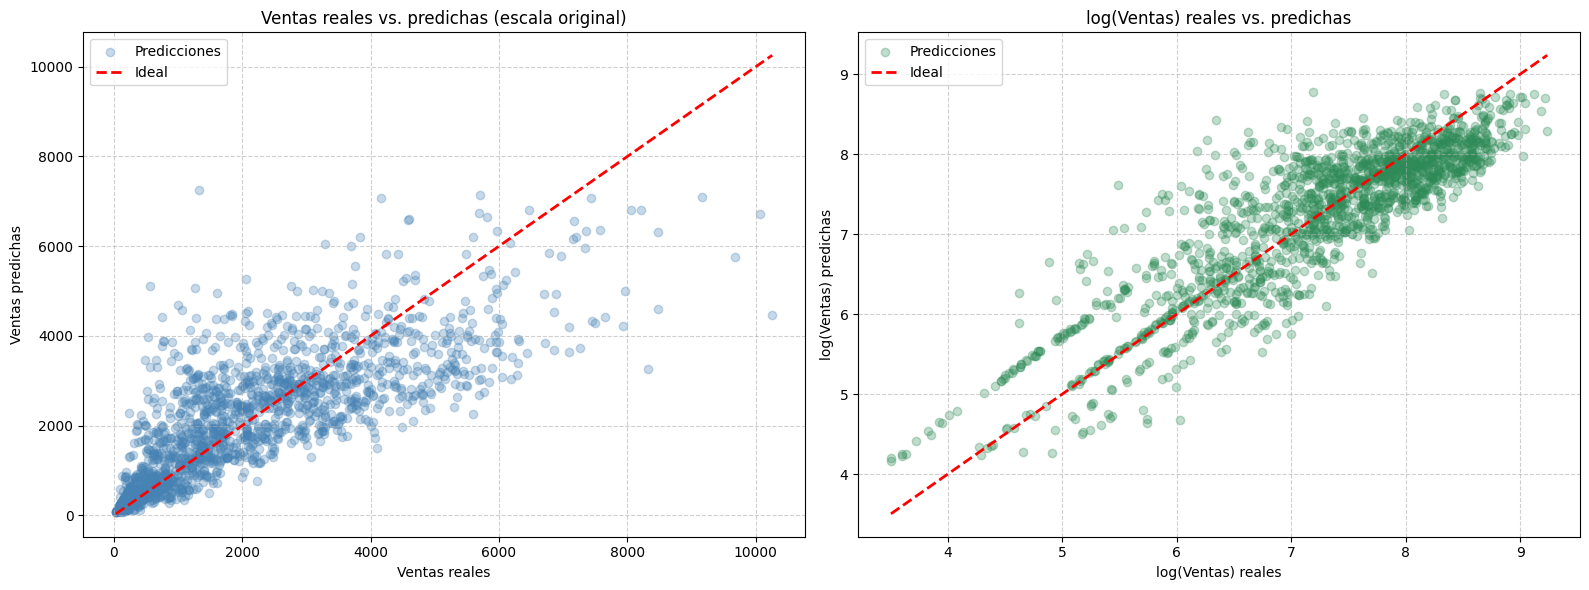

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Escala original
axes[0].scatter(real_sales, pred_sales, alpha=0.3, color='steelblue', label='Predicciones')
axes[0].plot([real_sales.min(), real_sales.max()], [real_sales.min(), real_sales.max()], '--r', linewidth=2, label='Ideal')
axes[0].set(title='Ventas reales vs. predichas (escala original)', xlabel='Ventas reales', ylabel='Ventas predichas')
axes[0].legend(); axes[0].grid(True, linestyle='--', alpha=0.6)

# Escala logarítmica
axes[1].scatter(ytest, predictions, alpha=0.3, color='seagreen', label='Predicciones')
axes[1].plot([ytest.min(), ytest.max()], [ytest.min(), ytest.max()], '--r', linewidth=2, label='Ideal')
axes[1].set(title='log(Ventas) reales vs. predichas', xlabel='log(Ventas) reales', ylabel='log(Ventas) predichas')
axes[1].legend(); axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 7. Interpretación de coeficientes

Un coeficiente positivo alto indica que esa característica impulsa las ventas hacia arriba; uno negativo, que las disminuye. Como el modelo trabaja con `log(ventas)` y variables escaladas a [0,1], los coeficientes se interpretan **en términos relativos** (cuál pesa más), no en pesos directos.

> **Ojo:** `Log_MRP` y las interacciones `Log_MRP_x_OUTxxx` están muy relacionadas entre sí (la suma de las interacciones es `Log_MRP`), así que el valor individual de esos coeficientes no debe interpretarse por separado. Lo que sí se puede leer bien son las variables categóricas.

In [36]:
nombres = lr_model.named_steps['columntransformer'].get_feature_names_out()
coefs = lr_model.named_steps['linearregression'].coef_

df_coef = pd.DataFrame({'Característica': nombres, 'Coeficiente': coefs}).sort_values('Coeficiente', ascending=False)

print('--- Factores que más AUMENTAN las ventas ---')
display(df_coef.head(5))
print('\n--- Factores que más DISMINUYEN las ventas ---')
display(df_coef.tail(5))

--- Factores que más AUMENTAN las ventas ---


,Característica,Coeficiente
2,num__Log_MRP,2.186992
23,cat__Outlet_Identifier_OUT046,1.058396
29,cat__Outlet_Type_Supermarket Type1,0.949656
31,cat__Outlet_Type_Supermarket Type3,0.811829
20,cat__Outlet_Identifier_OUT027,0.811829



--- Factores que más DISMINUYEN las ventas ---


,Característica,Coeficiente
28,cat__Outlet_Location_Type_Tier 3,-0.406058
26,cat__Outlet_Size_Small,-0.505058
24,cat__Outlet_Identifier_OUT049,-0.508646
12,num__Log_MRP_x_OUT046,-0.526182
19,cat__Outlet_Identifier_OUT019,-0.548742


## 8. Acceso a los pasos del pipeline

In [37]:
# Pasos ejecutados en el pipeline
lr_model.named_steps

{'columntransformer': ColumnTransformer(transformers=[('num',
                                  Pipeline(steps=[('simpleimputer',
                                                   SimpleImputer(strategy='median')),
                                                  ('minmaxscaler',
                                                   MinMaxScaler())]),
                                  <sklearn.compose._column_transformer.make_column_selector object at 0x79a0473b92b0>),
                                 ('cat',
                                  Pipeline(steps=[('simpleimputer',
                                                   SimpleImputer(strategy='most_frequent')),
                                                  ('onehotencoder',
                                                   OneHotEncoder(drop='first',
                                                                 handle_unknown='ignore',
                                                                 sparse_output=False))])

In [38]:
# Intercepción (beta_0)
lr_model.named_steps['linearregression'].intercept_

np.float64(5.008843566516402)

In [39]:
# Coeficientes (beta_1 ... beta_n): uno por cada predictor después del procesamiento
print('Número de coeficientes:', len(lr_model.named_steps['linearregression'].coef_))
lr_model.named_steps['linearregression'].coef_

Número de coeficientes: 34


array([-0.03184746,  0.04383366,  2.18699234, -0.00238257, -0.00881892,
        0.53302659,  0.3317404 ,  0.44536912,  0.16090756, -0.18407497,
        0.14264017, -0.18972728, -0.52618208,  0.13483995,  0.01350785,
        0.00973636, -0.00514409, -0.05906614,  0.20701918, -0.54874228,
        0.81182943,  0.13825059,  0.32586588,  1.05839616, -0.50864643,
        0.51020218, -0.5050581 ,  0.40505032, -0.40605778,  0.94965596,
        0.20701918,  0.81182943,  0.02487201,  0.01350785])

In [40]:
# Transformadores ejecutados
lr_model.named_steps['columntransformer']

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('minmaxscaler',
                                                  MinMaxScaler())]),
                                 <sklearn.compose._column_transformer.make_column_selector object at 0x79a0473b92b0>),
                                ('cat',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 <sklearn.compose._column_transformer.make_column_selector object at 0x79a03ebb7750>)])

In [42]:
# Mínimos usados por el MinMaxScaler en las variables numéricas
lr_model.named_steps['columntransformer'].named_transformers_['num'].named_steps['minmaxscaler'].min_

array([-0.13281075, -0.16666667, -1.60636673,  1.24634306,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ])

## 9. Conclusiones

* El **modelo base** (regresión lineal sobre los datos originales) obtiene R² ≈ 0.558 y RMSE ≈ 1144 en ventas originales.
* El **modelo mejorado** supera el objetivo de R² ≥ 0.70 en escala logarítmica y mejora también en la escala original de ventas (ver tabla del punto 5 para los valores exactos de esta ejecución).
* Las mejoras que más aportaron: limpiar los ceros de `Item_Visibility` y los nulos de `Item_Weight`/`Outlet_Size`, conservar `Outlet_Identifier`, crear `Item_Category`, aplicar logaritmo a ventas, precio y visibilidad, y agregar las interacciones precio × tienda.
* La diferencia entre el R² en escala logarítmica y en escala original es normal: al regresar a ventas reales, los errores de las ventas más altas pesan mucho más.
* El Random Forest de referencia **no supera** a la regresión lineal mejorada (ver tabla del punto 5), lo que indica que lo que más pesó fue la limpieza y la ingeniería de características, y que el límite del dataset es el **ruido propio de los datos** más que el tipo de modelo.